# CyberSentry — 04 · DL Attack Classification (Stage 2: What kind of attack?)

**Goal:** for every flow that Stage 1 flags as **Suspicious**, identify the **attack type** and give a **confidence score**.

**Input:** `data/processed/train|val|test.parquet`, `models/preprocessing/`, `models/ml/` (Stage-1 model)
**Shared code:** `src/dl_models.py` (model architectures, so the dashboard can rebuild the saved model)

**Classes:** the 14 attack types **plus BENIGN**. BENIGN is included on purpose: Stage 1 occasionally flags normal traffic, and Stage 2 gets a second chance to say "this is actually normal". BENIGN is capped to a sample so it doesn't drown out the attacks.

**Models compared** (deep learning candidates from the project plan):
- **MLP** — fully-connected network, treats each flow as a feature vector
- **1D-CNN** — convolution over the feature vector, learns local feature patterns
- **LSTM / GRU** — recurrent networks reading the features as a sequence
- **XGBoost (multi-class)** — *non-DL baseline*, to check whether deep learning actually adds value on this tabular data

**Evaluation:** accuracy, macro-F1 (treats every attack type equally, so rare attacks count), weighted-F1, per-class precision/recall/F1, confusion matrix, confidence analysis, and finally the **full Stage 1 → Stage 2 pipeline** on the test set.

*(Transformer was in the candidate list; it is left out here because on 32 tabular features it adds training cost on a CPU without a clear expected gain. Mention this as a scope decision / future work.)*

## 1. Setup

In [15]:
import copy
import json
import sys
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix)
from xgboost import XGBClassifier

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from dl_models import build_model, log_transform, predict_proba

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)

PROC_DIR = ROOT / "data" / "processed"
PRE_DIR = ROOT / "models" / "preprocessing"
ML_DIR = ROOT / "models" / "ml"
DL_DIR = ROOT / "models" / "dl"
DL_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = json.load(open(PRE_DIR / "selected_features.json"))["selected_features"]
train = pd.read_parquet(PROC_DIR / "train.parquet")
val = pd.read_parquet(PROC_DIR / "val.parquet")
test = pd.read_parquet(PROC_DIR / "test.parquet")

print(f"PyTorch {torch.__version__} | device: CPU | threads: {torch.get_num_threads()}")
print(f"{len(FEATURES)} features | train {len(train):,} | val {len(val):,} | test {len(test):,}")

PyTorch 2.14.1+cpu | device: CPU | threads: 8
32 features | train 1,748,729 | val 374,728 | test 374,728


## 2. Build the Stage-2 datasets

All attack rows are kept. BENIGN is capped (100k train, 20k val/test), which is enough for the model to learn what "normal" looks like without it dominating every batch.

In [16]:
BENIGN_CAP = {"train": 100_000, "val": 20_000, "test": 20_000}

MERGE = {"Web Attack - Brute Force": "Web Attack",
         "Web Attack - XSS": "Web Attack",
         "Web Attack - Sql Injection": "Web Attack"}
for df in (train, val, test):
    df["Label"] = df["Label"].replace(MERGE)

def stage2_subset(df, cap):
    attacks = df[df["Label"] != "BENIGN"]
    benign = df[df["Label"] == "BENIGN"]
    benign = benign.sample(min(cap, len(benign)), random_state=SEED)
    return pd.concat([attacks, benign]).sample(frac=1, random_state=SEED).reset_index(drop=True)

tr = stage2_subset(train, BENIGN_CAP["train"])
va = stage2_subset(val, BENIGN_CAP["val"])
te = stage2_subset(test, BENIGN_CAP["test"])

CLASSES = sorted(tr["Label"].unique())
cls_to_idx = {c: i for i, c in enumerate(CLASSES)}
y_tr = tr["Label"].map(cls_to_idx).values
y_va = va["Label"].map(cls_to_idx).values
y_te = te["Label"].map(cls_to_idx).values

counts = pd.DataFrame({"train": tr["Label"].value_counts(), "val": va["Label"].value_counts(),
                       "test": te["Label"].value_counts()}).fillna(0).astype(int).sort_values("train", ascending=False)
print(f"{len(CLASSES)} classes")
counts

13 classes


,train,val,test
Label,,,
DoS Hulk,120992,25927,25927
BENIGN,100000,20000,20000
DDoS,89610,19202,19202
PortScan,63486,13604,13604
DoS GoldenEye,7200,1543,1543
FTP-Patator,4152,889,890
DoS slowloris,3769,808,808
DoS Slowhttptest,3660,784,784
SSH-Patator,2253,483,483


## 3. Feature transformation for neural networks

Flow features are extremely skewed (e.g. `Flow Bytes/s` ranges from 0 to billions). Neural networks train badly on such ranges, so we apply a **signed log transform** and then standardise. The DL scaler is fitted on the **training set only** and saved with the model.

(Tree models like XGBoost don't need this, so the baseline uses the raw features.)

In [17]:
dl_scaler = StandardScaler().fit(log_transform(tr[FEATURES]))
def transform(df):
    return dl_scaler.transform(log_transform(df[FEATURES])).astype(np.float32)

X_tr, X_va, X_te = transform(tr), transform(va), transform(te)
joblib.dump(dl_scaler, DL_DIR / "dl_scaler.joblib")
print("Transformed. Value range after scaling:", round(float(X_tr.min()), 2), "to", round(float(X_tr.max()), 2))

Transformed. Value range after scaling: -90.02 to 16.05


## 4. Handling class imbalance

Even after capping BENIGN, DoS Hulk has ~100k+ training rows while Heartbleed has about 8. We use a **class-weighted loss**: weights proportional to `1 / sqrt(class frequency)`. The square root keeps rare classes important without making the model obsessed with 8 Heartbleed samples.

In [18]:
freq = np.bincount(y_tr, minlength=len(CLASSES))
weights = 1.0 / np.sqrt(freq)
weights = weights / weights.mean()
class_weights = torch.tensor(weights, dtype=torch.float32)
pd.DataFrame({"train rows": freq, "loss weight": weights.round(2)}, index=CLASSES).sort_values("train rows", ascending=False)

,train rows,loss weight
DoS Hulk,120992,0.05
BENIGN,100000,0.06
DDoS,89610,0.06
PortScan,63486,0.07
DoS GoldenEye,7200,0.22
FTP-Patator,4152,0.29
DoS slowloris,3769,0.30
DoS Slowhttptest,3660,0.31
SSH-Patator,2253,0.39
Web Attack,1500,0.48


## 5. Training loop (with early stopping)

- Optimiser: Adam (lr = 0.001), batch size 1024
- After each epoch we compute **validation macro-F1**; training stops when it hasn't improved for 4 epochs, and the best epoch's weights are kept
- Max 30 epochs (15 for LSTM/GRU, which are much slower on a CPU)

In [19]:
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(y_tr).long()),
                          batch_size=1024, shuffle=True)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

def train_model(arch, max_epochs=30, patience=4):
    torch.manual_seed(SEED)
    model = build_model(arch, len(FEATURES), len(CLASSES))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    best_f1, best_state, bad, history = -1.0, None, 0, []
    t_start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train(); t0 = time.time(); total = 0.0
        for xb, yb in train_loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * len(xb)
        val_pred = predict_proba(model, X_va).argmax(1)
        f1 = f1_score(y_va, val_pred, average="macro")
        history.append({"epoch": epoch, "train_loss": total / len(X_tr), "val_macro_f1": f1})
        print(f"  {arch:<7} epoch {epoch:2d} | loss {total / len(X_tr):.4f} | val macro-F1 {f1:.4f} | {time.time() - t0:.0f}s")
        if f1 > best_f1 + 1e-4:
            best_f1, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop (best val macro-F1 {best_f1:.4f})")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_f1, time.time() - t_start

## 6. Train the deep learning models

In [20]:
ARCHS = ["MLP", "1D-CNN", "LSTM", "GRU"]
models, histories, val_f1, train_times, test_probs = {}, {}, {}, {}, {}

for arch in ARCHS:
    print(f"\n=== {arch} ===")
    m, h, f1, t = train_model(arch, max_epochs=15 if arch in ("LSTM", "GRU") else 30)
    models[arch], histories[arch], val_f1[arch], train_times[arch] = m, h, f1, t
    t0 = time.time(); test_probs[arch] = predict_proba(m, X_te)
    print(f"  done in {t / 60:.1f} min | best val macro-F1 {f1:.4f}")


=== MLP ===
  MLP     epoch  1 | loss 0.3670 | val macro-F1 0.7771 | 8s
  MLP     epoch  2 | loss 0.0956 | val macro-F1 0.8601 | 7s
  MLP     epoch  3 | loss 0.0722 | val macro-F1 0.8590 | 7s
  MLP     epoch  4 | loss 0.0591 | val macro-F1 0.8539 | 7s
  MLP     epoch  5 | loss 0.0536 | val macro-F1 0.8690 | 7s
  MLP     epoch  6 | loss 0.0489 | val macro-F1 0.8698 | 7s
  MLP     epoch  7 | loss 0.0457 | val macro-F1 0.8882 | 7s
  MLP     epoch  8 | loss 0.0429 | val macro-F1 0.8674 | 7s
  MLP     epoch  9 | loss 0.0406 | val macro-F1 0.8746 | 7s
  MLP     epoch 10 | loss 0.0388 | val macro-F1 0.8577 | 7s
  MLP     epoch 11 | loss 0.0388 | val macro-F1 0.8800 | 7s
  early stop (best val macro-F1 0.8882)
  done in 1.3 min | best val macro-F1 0.8882

=== 1D-CNN ===
  1D-CNN  epoch  1 | loss 0.1625 | val macro-F1 0.8823 | 14s
  1D-CNN  epoch  2 | loss 0.0487 | val macro-F1 0.8700 | 14s
  1D-CNN  epoch  3 | loss 0.0384 | val macro-F1 0.8941 | 15s
  1D-CNN  epoch  4 | loss 0.0347 | val macr

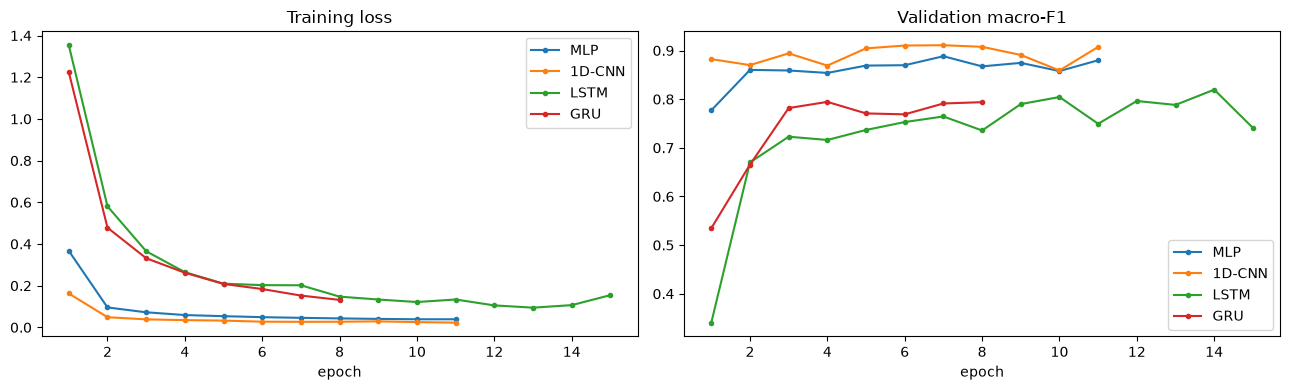

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for arch, h in histories.items():
    ax[0].plot(h["epoch"], h["train_loss"], marker=".", label=arch)
    ax[1].plot(h["epoch"], h["val_macro_f1"], marker=".", label=arch)
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 7. Baseline: XGBoost multi-class (non-DL)

Same classes, same rows, same class weighting. If XGBoost matches or beats the neural networks, that's an honest and common finding on tabular data, and worth stating in the report.

In [22]:
sample_w = weights[y_tr]
t0 = time.time()
xgb_mc = XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=8, tree_method="hist",
                       eval_metric="mlogloss", early_stopping_rounds=20, n_jobs=-1, random_state=SEED)
xgb_mc.fit(tr[FEATURES], y_tr, sample_weight=sample_w, eval_set=[(va[FEATURES], y_va)], verbose=False)
train_times["XGBoost (baseline)"] = time.time() - t0
val_f1["XGBoost (baseline)"] = f1_score(y_va, xgb_mc.predict(va[FEATURES]), average="macro")
test_probs["XGBoost (baseline)"] = xgb_mc.predict_proba(te[FEATURES])
print(f"XGBoost baseline: val macro-F1 {val_f1['XGBoost (baseline)']:.4f} | {train_times['XGBoost (baseline)']:.0f}s")

XGBoost baseline: val macro-F1 0.9893 | 63s


## 8. Comparison on the test set

In [23]:
rows = {}
for name, probs in test_probs.items():
    pred = probs.argmax(1)
    rows[name] = {
        "Val macro-F1": val_f1[name],
        "Accuracy": accuracy_score(y_te, pred),
        "Macro precision": precision_score(y_te, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(y_te, pred, average="macro", zero_division=0),
        "Macro-F1": f1_score(y_te, pred, average="macro"),
        "Weighted-F1": f1_score(y_te, pred, average="weighted"),
        "Mean confidence": probs.max(1).mean(),
        "Parameters": sum(p.numel() for p in models[name].parameters()) if name in models else np.nan,
        "Train time (min)": train_times[name] / 60,
    }
dl_comparison = pd.DataFrame(rows).T.sort_values("Val macro-F1", ascending=False)
dl_comparison.style.format({c: "{:.4f}" for c in dl_comparison.columns if c not in ("Parameters", "Train time (min)")}
                           | {"Parameters": "{:,.0f}", "Train time (min)": "{:.1f}"}) \
                   .highlight_max(subset=["Val macro-F1", "Accuracy", "Macro-F1", "Weighted-F1"], color="#2a6f4a")

,Val macro-F1,Accuracy,Macro precision,Macro recall,Macro-F1,Weighted-F1,Mean confidence,Parameters,Train time (min)
XGBoost (baseline),0.9893,0.9992,0.9557,0.9977,0.9703,0.9993,0.9992,nan,1.1
1D-CNN,0.9109,0.9958,0.9021,0.9528,0.8982,0.9960,0.9957,"139,405",2.7
MLP,0.8882,0.9923,0.8598,0.9630,0.8902,0.9931,0.9937,"51,341",1.3
LSTM,0.8195,0.9795,0.8127,0.9099,0.8218,0.9812,0.9858,"17,997",4.0
GRU,0.7944,0.9674,0.7501,0.8389,0.7760,0.9673,0.9529,"13,709",3.5


## 9. Best DL model: per-class results

The model is chosen by **validation macro-F1** among the four deep learning models (the XGBoost baseline is a reference point, not a candidate for this DL stage).

In [24]:
BEST = max(ARCHS, key=lambda a: val_f1[a])
best_probs = test_probs[BEST]
best_pred = best_probs.argmax(1)
print(f"Best DL model: {BEST} (val macro-F1 {val_f1[BEST]:.4f})\n")
print(classification_report(y_te, best_pred, labels=range(len(CLASSES)), target_names=CLASSES, digits=4, zero_division=0))

Best DL model: 1D-CNN (val macro-F1 0.9109)

                  precision    recall  f1-score   support

          BENIGN     0.9989    0.9884    0.9936     20000
             Bot     0.6597    0.9692    0.7850       292
            DDoS     0.9998    0.9998    0.9998     19202
   DoS GoldenEye     0.9374    1.0000    0.9677      1543
        DoS Hulk     0.9987    0.9978    0.9983     25927
DoS Slowhttptest     0.9873    0.9885    0.9879       784
   DoS slowloris     0.9950    0.9814    0.9882       808
     FTP-Patator     0.9922    0.9978    0.9950       890
      Heartbleed     0.2000    1.0000    0.3333         1
    Infiltration     1.0000    0.5000    0.6667         6
        PortScan     0.9996    0.9993    0.9994     13604
     SSH-Patator     0.9835    0.9855    0.9845       483
      Web Attack     0.9752    0.9782    0.9767       321

        accuracy                         0.9958     83861
       macro avg     0.9021    0.9528    0.8982     83861
    weighted avg     0.99

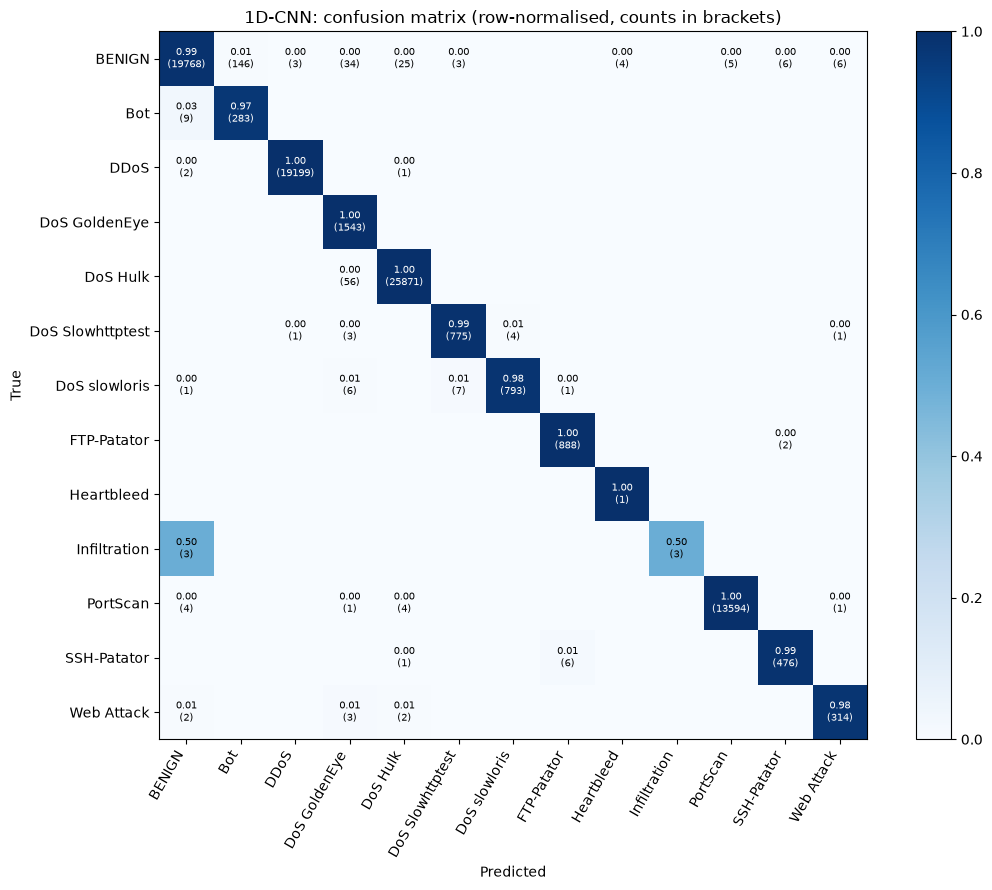

In [25]:
cm = confusion_matrix(y_te, best_pred, labels=range(len(CLASSES)))
cm_norm = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=60, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if cm[i, j]:
            ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"{BEST}: confusion matrix (row-normalised, counts in brackets)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

## 10. Is the confidence score trustworthy?

The dashboard will show a **confidence** for each prediction, so it must mean something: high-confidence predictions should almost always be right. Predictions below the review threshold are marked **"needs analyst review"**, which matches the project's goal of assisting, not replacing, the analyst.

Below 70% confidence (sent to analyst review): 0.61% of predictions
Accuracy of confident predictions (>= 70%): 99.8260%
Accuracy of low-confidence predictions: 59.2955%



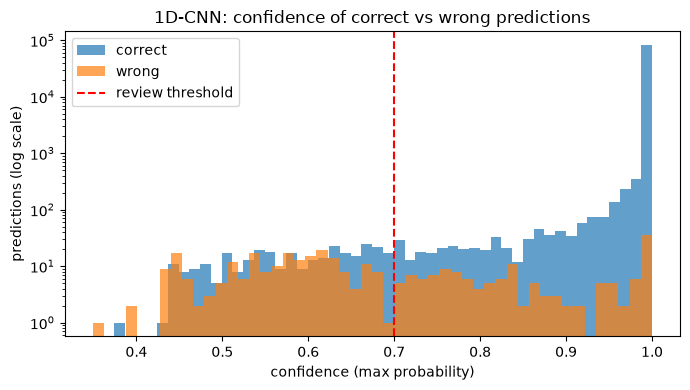

,predictions,accuracy in band,share of predictions
band,,,
<50%,89,52.81%,0.11%
50-70%,422,60.66%,0.50%
70-90%,487,82.14%,0.58%
90-99%,"1,124",97.86%,1.34%
>=99%,"81,739",99.96%,97.47%


In [26]:
REVIEW_THRESHOLD = 0.70
conf = best_probs.max(1)
correct = best_pred == y_te

bands = pd.cut(conf, [0, 0.5, 0.7, 0.9, 0.99, 1.0001], labels=["<50%", "50-70%", "70-90%", "90-99%", ">=99%"])
calib = pd.DataFrame({"band": bands, "correct": correct}).groupby("band", observed=False)["correct"].agg(["count", "mean"])
calib.columns = ["predictions", "accuracy in band"]
calib["share of predictions"] = calib["predictions"] / calib["predictions"].sum()
print(f"Below {REVIEW_THRESHOLD:.0%} confidence (sent to analyst review): {(conf < REVIEW_THRESHOLD).mean():.2%} of predictions")
print(f"Accuracy of confident predictions (>= {REVIEW_THRESHOLD:.0%}): {correct[conf >= REVIEW_THRESHOLD].mean():.4%}")
print(f"Accuracy of low-confidence predictions: {correct[conf < REVIEW_THRESHOLD].mean() if (conf < REVIEW_THRESHOLD).any() else float('nan'):.4%}\n")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(conf[correct], bins=50, alpha=0.7, label="correct", log=True)
ax.hist(conf[~correct], bins=50, alpha=0.7, label="wrong", log=True)
ax.axvline(REVIEW_THRESHOLD, color="red", ls="--", label="review threshold")
ax.set_xlabel("confidence (max probability)"); ax.set_ylabel("predictions (log scale)")
ax.set_title(f"{BEST}: confidence of correct vs wrong predictions"); ax.legend(); plt.tight_layout(); plt.show()
calib.style.format({"accuracy in band": "{:.2%}", "share of predictions": "{:.2%}", "predictions": "{:,}"})

## 11. Full pipeline on the test set: Stage 1 (ML) → Stage 2 (DL)

This is how CyberSentry will actually run:
1. **Stage 1** (saved ML model) scores every flow in the full test set → Normal or Suspicious
2. Flows flagged **Suspicious** go to **Stage 2** (best DL model) → attack type + confidence
3. Flows not flagged are reported as BENIGN

The result is compared with the true labels, giving the end-to-end performance of the system.

In [27]:
s1_meta = json.load(open(ML_DIR / "stage1_meta.json"))
s1_model = joblib.load(ML_DIR / "stage1_model.joblib")
X_s1 = test[s1_meta["features"]]

if s1_meta["model"] == "Isolation Forest":
    s1_score = -s1_model.score_samples(X_s1)
elif s1_meta["model"] == "One-Class SVM":
    pre_scaler = joblib.load(PRE_DIR / "scaler.joblib")
    s1_score = -s1_model.decision_function(pre_scaler.transform(X_s1.astype(np.float64)))
else:
    s1_score = s1_model.predict_proba(X_s1)[:, 1]
flagged = s1_score >= s1_meta["threshold"]

t0 = time.time()
final = np.full(len(test), "BENIGN", dtype=object)
final_conf = np.ones(len(test))
if flagged.any():
    probs = predict_proba(models[BEST], transform(test.loc[flagged]))
    final[flagged] = np.array(CLASSES, dtype=object)[probs.argmax(1)]
    final_conf[flagged] = probs.max(1)
pipeline_time = time.time() - t0
y_true = test["Label"].values

print(f"Stage 1 ({s1_meta['model']}) flagged {flagged.sum():,} of {len(test):,} test flows ({flagged.mean():.2%})")
print(f"Stage 2 ({BEST}) classified them in {pipeline_time:.1f}s\n")
print(f"END-TO-END  accuracy {accuracy_score(y_true, final):.4f} | macro-F1 {f1_score(y_true, final, average='macro'):.4f} "
      f"| weighted-F1 {f1_score(y_true, final, average='weighted'):.4f}\n")
print(classification_report(y_true, final, digits=4, zero_division=0))

Stage 1 (XGBoost) flagged 64,129 of 374,728 test flows (17.11%)
Stage 2 (1D-CNN) classified them in 0.7s

END-TO-END  accuracy 0.9989 | macro-F1 0.9533 | weighted-F1 0.9989

                  precision    recall  f1-score   support

          BENIGN     0.9999    0.9991    0.9995    310867
             Bot     0.7437    0.9144    0.8203       292
            DDoS     0.9999    0.9998    0.9998     19202
   DoS GoldenEye     0.9536    1.0000    0.9763      1543
        DoS Hulk     0.9985    0.9978    0.9981     25927
DoS Slowhttptest     0.9785    0.9872    0.9829       784
   DoS slowloris     0.9950    0.9814    0.9882       808
     FTP-Patator     0.9922    0.9978    0.9950       890
      Heartbleed     1.0000    1.0000    1.0000         1
    Infiltration     1.0000    0.5000    0.6667         6
        PortScan     0.9894    0.9993    0.9943     13604
     SSH-Patator     0.9958    0.9855    0.9906       483
      Web Attack     0.9905    0.9720    0.9811       321

        accu

## 12. Save the Stage-2 model

In [28]:
torch.save({
    "arch": BEST,
    "state_dict": models[BEST].state_dict(),
    "n_features": len(FEATURES),
    "features": FEATURES,
    "classes": CLASSES,
}, DL_DIR / "stage2_model.pt")

stage2_meta = {
    "model": BEST,
    "features": FEATURES,
    "classes": CLASSES,
    "preprocessing": "signed log1p, then models/dl/dl_scaler.joblib (fitted on train only)",
    "review_threshold": REVIEW_THRESHOLD,
    "val_macro_f1": float(val_f1[BEST]),
    "test_macro_f1": float(f1_score(y_te, best_pred, average="macro")),
    "test_accuracy": float(accuracy_score(y_te, best_pred)),
    "pipeline_test_macro_f1": float(f1_score(y_true, final, average="macro")),
    "pipeline_test_accuracy": float(accuracy_score(y_true, final)),
}
json.dump(stage2_meta, open(DL_DIR / "stage2_meta.json", "w"), indent=2)
dl_comparison.to_csv(DL_DIR / "dl_comparison.csv")
print("Saved to", DL_DIR)
for f in sorted(DL_DIR.iterdir()):
    print(f"  {f.name:<22} {f.stat().st_size / 1e6:.2f} MB")

Saved to d:\Engineering\SEM 5\MINI PROJECT II\Cybersentry\models\dl
  dl_comparison.csv      0.00 MB
  dl_scaler.joblib       0.00 MB
  stage2_meta.json       0.00 MB
  stage2_model.pt        0.57 MB


## 13. Summary

*(Fill in from the outputs above.)*

- **Best DL model:** see section 9, with test macro-F1 and accuracy from section 8
- **DL vs XGBoost baseline:** section 8 — whether deep learning beat the tree model on this tabular data
- **Hardest attack types:** from the per-class report (usually the rare/similar ones: Web Attack Brute Force vs XSS, Bot, Infiltration)
- **Confidence:** share of predictions sent to analyst review, and accuracy of confident predictions (section 10)
- **Full pipeline (section 11):** end-to-end accuracy and macro-F1 of Stage 1 → Stage 2 on the untouched test set

Next: Stage 3 — the GenAI module turns each prediction (attack type, confidence, key feature values) into an explanation and an incident report, grounded only in this evidence.